# DAT200 – Compulsory Assignment 4

## Customer Churn Prediction

Develop and evaluate machine learning classifiers to predict customer churn using customer subscription and phone usage data.

The main evaluation metric is the macro-averaged F1-score. We will compare different classifiers and optimise their hyperparameters using cross-validation and scikit-learn pipelines.

## 1. Imports and Data Loading

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:

# Load the datasets
train_df = pd.read_csv("../dat-200-ca-4-h-2026/trainCA4DAT200.csv")
test_df = pd.read_csv("../dat-200-ca-4-h-2026/testCA4DAT200.csv")
sample_submission = pd.read_csv("../dat-200-ca-4-h-2026/sample_submissionCA4DAT200.csv")

# Check dataset dimensions
print("Training data:", train_df.shape)
print("Test data:", test_df.shape)
print("Sample submission:", sample_submission.shape)

# Display the first five rows
display(train_df.head())

Training data: (3500, 21)
Test data: (1500, 20)
Sample submission: (1500, 2)


,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


## 2. Exploratory Data Analysis (EDA)

Before training machine learning models, we explore the dataset to understand its structure, feature distributions, and potential data quality issues.

We examine data types, missing values, duplicate records, descriptive statistics, and the distribution of the target variable (`Churn`). These findings will guide our preprocessing and model selection decisions.

In [10]:
# Display general information about the training dataset
# This includes column names, data types, and non-null values
train_df.info()

# Check for missing values in each column
# Missing values may need to be handled before training the models
print("\nMissing values:")
print(train_df.isnull().sum())

# Check whether the dataset contains duplicate rows
print("\nDuplicate rows:", train_df.duplicated().sum())

# Check whether any customer IDs appear more than once
# Each customer should have a unique identifier
print("Duplicate Customer IDs:", train_df["CustomerId"].duplicated().sum())

# Display descriptive statistics for all columns
# This helps us understand the distributions and identify unusual values
display(train_df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerId            3500 non-null   int64  
 1   State                 3500 non-null   str    
 2   AccountLength         3500 non-null   int64  
 3   AreaCode              3500 non-null   int64  
 4   InternationalPlan     3500 non-null   str    
 5   VoiceMailPlan         3500 non-null   str    
 6   NumVoiceMailMessages  3500 non-null   int64  
 7   DayMinutes            3500 non-null   float64
 8   DayCalls              3500 non-null   int64  
 9   DayCharge             3500 non-null   float64
 10  EveMinutes            3500 non-null   float64
 11  EveCalls              3500 non-null   int64  
 12  EveCharge             3500 non-null   float64
 13  NightMinutes          3500 non-null   float64
 14  NightCalls            3500 non-null   int64  
 15  NightCharge           3500 non-n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerId,3500.0,NaN,NaN,NaN,545925.360857,261478.546087,101267.0,322381.0,536375.5,775246.75,999391.0
State,3500,51,WV,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccountLength,3500.0,NaN,NaN,NaN,99.996571,39.471509,1.0,73.0,100.0,126.0,243.0
AreaCode,3500.0,NaN,NaN,NaN,436.915429,42.16918,408.0,415.0,415.0,415.0,510.0
InternationalPlan,3500,2,no,3168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VoiceMailPlan,3500,2,no,2530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NumVoiceMailMessages,3500.0,NaN,NaN,NaN,8.112,13.728371,0.0,0.0,0.0,19.0,52.0
DayMinutes,3500.0,NaN,NaN,NaN,180.292429,53.764503,0.0,143.7,179.7,216.525,351.5
DayCalls,3500.0,NaN,NaN,NaN,100.016286,19.852587,0.0,87.0,100.0,113.0,163.0
DayCharge,3500.0,NaN,NaN,NaN,30.650306,9.139923,0.0,24.43,30.55,36.8125,59.76


### 2.2 Target Variable Distribution

We examine the distribution of the target variable to identify possible class imbalance. This is important because an imbalanced dataset can lead to misleading accuracy scores.

Macro-averaged F1-score is used as the primary evaluation metric, as required by the assignment.

Churn counts:
Churn
0    3005
1     495
Name: count, dtype: int64

Churn percentages:
Churn
0    85.86
1    14.14
Name: proportion, dtype: float64


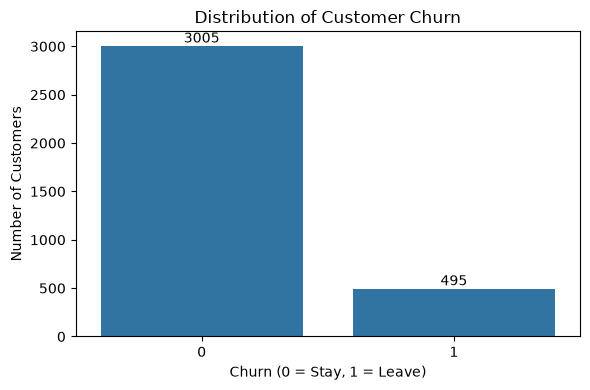

In [11]:
# Count the number of customers in each churn class
# Churn = 0 means the customer stays, and Churn = 1 means the customer leaves
churn_counts = train_df["Churn"].value_counts().sort_index()

# Calculate the percentage of customers in each class
# normalize=True returns proportions instead of counts
churn_percentages = (
    train_df["Churn"].value_counts(normalize=True).sort_index() * 100
)

# Display the class counts and percentages
print("Churn counts:")
print(churn_counts)

print("\nChurn percentages:")
print(churn_percentages.round(2))

# Create a bar chart to visualize the distribution of the target variable
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=train_df, x="Churn")

# Display the number of customers above each bar
for container in ax.containers:
    ax.bar_label(container)

# Add a title and axis labels to make the plot easier to interpret
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn (0 = Stay, 1 = Leave)")
plt.ylabel("Number of Customers")

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()

### 2.3 Numerical Feature Distributions

We use histograms to examine the distributions of numerical features. This helps us identify patterns, skewed distributions, and potentially unusual values that may require further investigation during preprocessing.

In [ ]:
# Select numerical features for exploration
# CustomerId is excluded because it is only an identifier
# AreaCode is excluded because it represents a category
# Churn is excluded because it is the target variable
numerical_features = train_df.select_dtypes(include=np.number).columns.drop(
    ["CustomerId", "AreaCode", "Churn"]
)

# Plot histograms to examine the distribution of numerical features
train_df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

# Add a title and adjust the layout
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### 2.4 Categorical Features and Churn

We investigate the relationship between categorical features and customer churn. Comparing churn rates across subscription plans may help identify features that are useful for classification.

In [ ]:
# Select subscription plan features for comparison
categorical_features = ["InternationalPlan", "VoiceMailPlan"]

# Create plots to compare churn rates across subscription plans
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, feature in enumerate(categorical_features):

    # Calculate the average churn rate for each category
    # Since Churn is binary, the mean represents the proportion who leave
    churn_rate = train_df.groupby(feature)["Churn"].mean() * 100

    # Plot the churn rate for each category
    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values,
        ax=axes[i]
    )

    # Add titles and labels
    axes[i].set_title(f"Churn Rate by {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Churn Rate (%)")

# Adjust spacing and display the plots
plt.tight_layout()
plt.show()

### 2.5 Correlation Analysis

We use a correlation heatmap to investigate linear relationships between numerical features. Strong correlations may indicate redundant information, which could influence our feature selection and dimensionality reduction decisions.

In [ ]:
# Calculate correlations between numerical variables
# Exclude CustomerId and AreaCode because they are identifiers/categories
correlation_data = train_df.drop(
    columns=["CustomerId", "AreaCode"]
)

# Calculate the Pearson correlation matrix
corr_matrix = correlation_data.corr(numeric_only=True)

# Create a heatmap to visualize correlations
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

# Add a title and adjust the layout
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### 2.6 Outlier Detection

Boxplots are used to identify potential outliers in numerical features. Unusual observations are not necessarily errors, so we will examine them before deciding whether any data cleaning is needed.

In [ ]:
# Select numerical features to investigate for possible outliers
selected_features = [
    "AccountLength",
    "DayMinutes",
    "EveMinutes",
    "NightMinutes",
    "IntlMinutes",
    "CustomerServiceCalls"
]

# Create boxplots for the selected features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Flatten the axes array to simplify plotting
axes = axes.flatten()

for i, feature in enumerate(selected_features):

    # Create a boxplot for each numerical feature
    sns.boxplot(
        y=train_df[feature],
        ax=axes[i]
    )

    # Add the feature name as the title
    axes[i].set_title(feature)

# Adjust spacing and display the plots
plt.tight_layout()
plt.show()